## Load the Excel sales file with read_excel

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
orders = pd.read_excel("retail_abroad.xlsx")

## Check the shape and the bad rows

In [2]:
print(orders.shape)
print((orders["Quantity"] <= 0).sum())
print((orders["UnitPrice"] <= 0).sum())

(46431, 8)
1432
18


## Clean the data, add Sales, save sales_clean.csv

In [3]:
good = orders[orders["Quantity"] > 0]
good = good[good["UnitPrice"] > 0].copy()
price = good["UnitPrice"]
good["Sales"] = good["Quantity"] * price
print(len(good), round(good["Sales"].sum()))
good.to_csv("sales_clean.csv", index=False)

44981 1641462


## Group by country and rank the sales

In [4]:
top = good.groupby("Country")["Sales"].sum()
top = top.sort_values().tail(8) / 1000
print(top.round())

Country
Belgium         41.0
Switzerland     57.0
Spain           62.0
Australia      139.0
France         210.0
Germany        229.0
EIRE           283.0
Netherlands    285.0
Name: Sales, dtype: float64


## Ranked horizontal bar chart with barh and bar_label

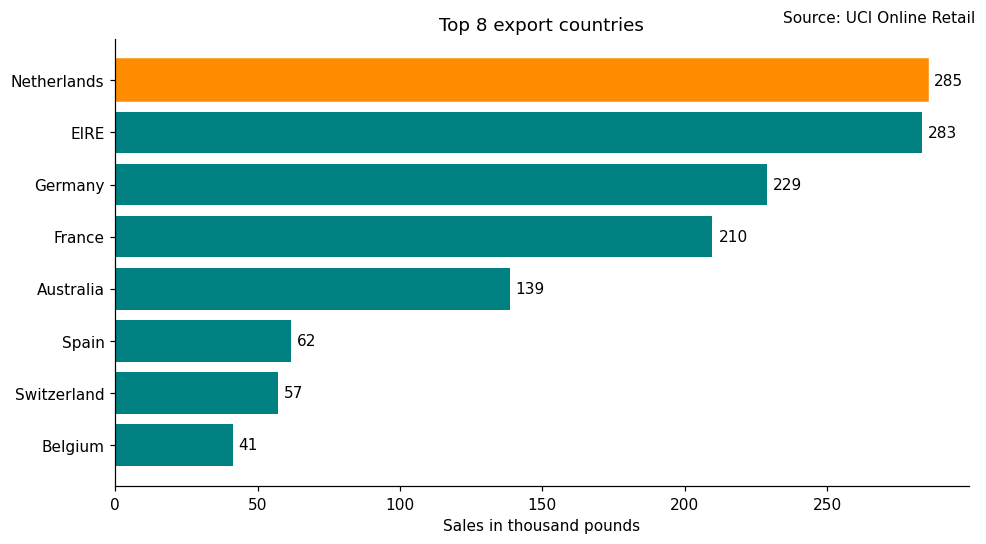

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top.index, top, color="teal")
bars[-1].set_color("darkorange")
ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set_title("Top 8 export countries")
ax.set_xlabel("Sales in thousand pounds")
ax.spines[["top", "right"]].set_visible(False)
src = "Source: UCI Online Retail"
fig.text(0.99, 0.96, src, ha="right")
fig.tight_layout()
plt.show()

## Monthly sales table with to_period and pivot_table

In [6]:
good["Month"] = good["InvoiceDate"].dt.to_period("M")
year = good[good["Month"] < "2011-12"]
four = ["Netherlands", "EIRE", "Germany", "France"]
part = year[year["Country"].isin(four)]
table = part.pivot_table("Sales", "Month", "Country", "sum")
table = table[four] / 1000
print(table.round().tail(3))
table.to_csv("monthly.csv")

Country  Netherlands  EIRE  Germany  France
Month                                      
2011-09         27.0  43.0     18.0    23.0
2011-10         41.0  24.0     32.0    33.0
2011-11         26.0  31.0     28.0    32.0
